In [20]:
import uproot
import numpy as np

def get_daily_count_for_detector(
    detector,
    base_path="dayabay_full_dataset_root_1-0-0/root/dayabay_dataset/"
):
    root_file = f"{base_path}dayabay_events_{detector}.root"

    with uproot.open(root_file) as f:
        days = f["events"]["day"].array(library="np")

    counts = np.bincount(days.astype(np.int64))

    return {day: int(count) for day, count in enumerate(counts)}

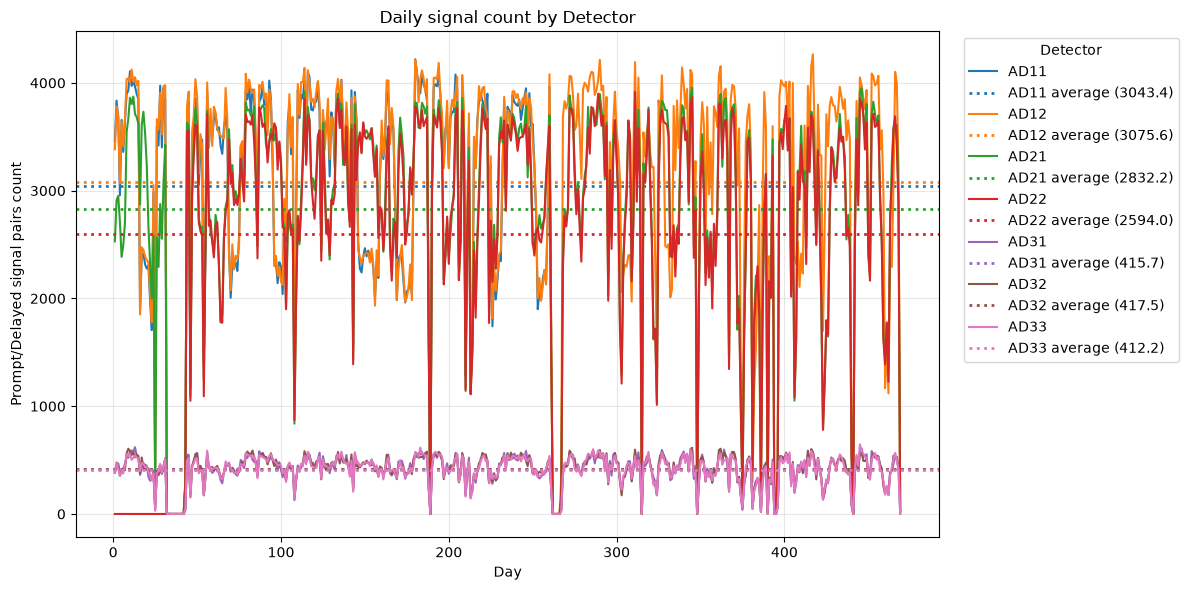

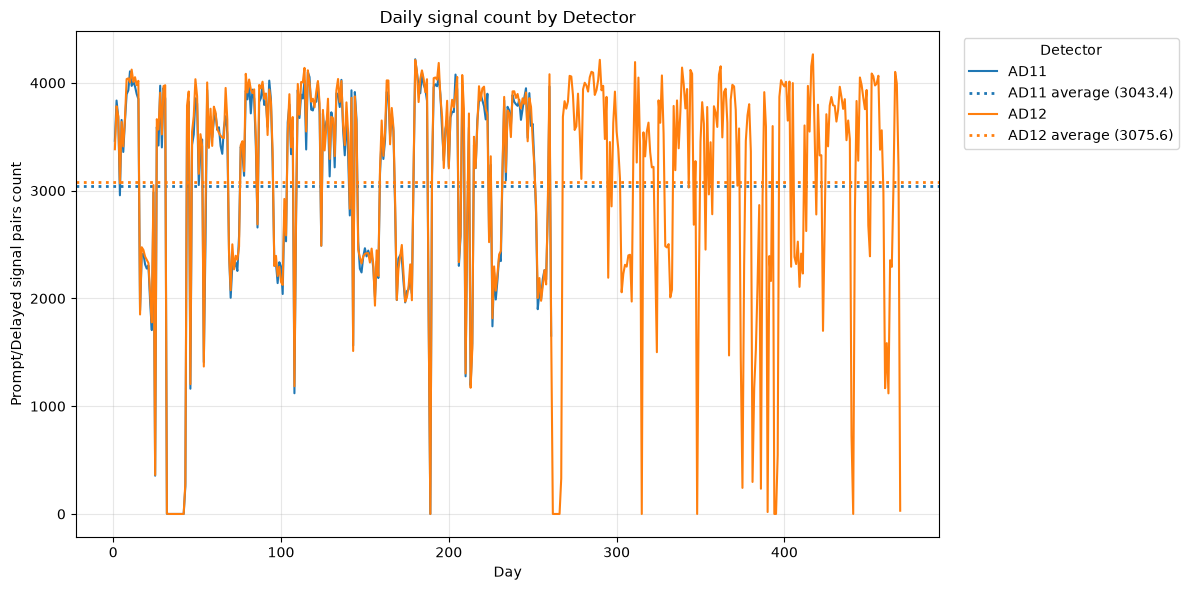

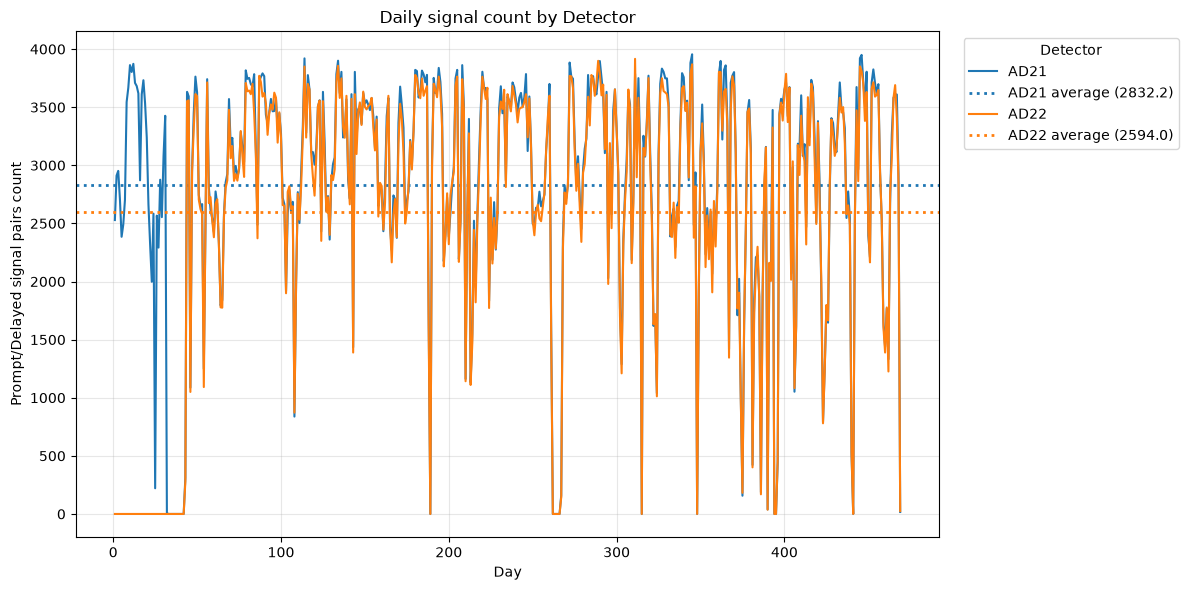

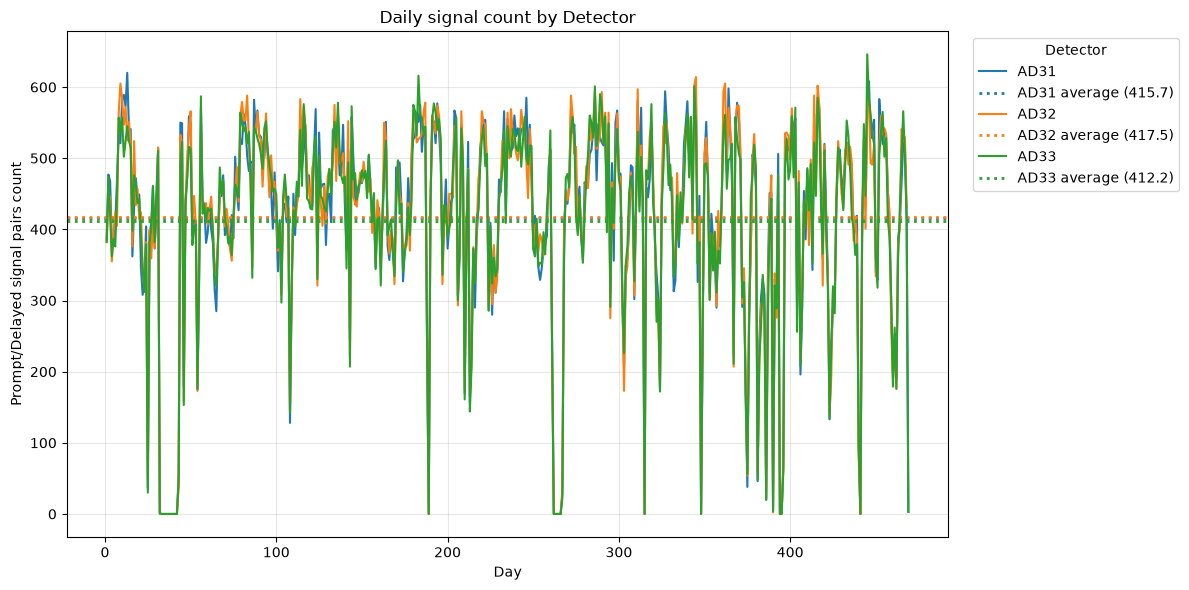

In [21]:
import matplotlib.pyplot as plt

list_of_list_of_detectors = [
    ["AD11", "AD12", "AD21", "AD22", "AD31", "AD32", "AD33"],
    ["AD11", "AD12"],
    ["AD21", "AD22"],
    ["AD31", "AD32", "AD33"]
]

for detectors in list_of_list_of_detectors:
    fig, ax = plt.subplots(figsize=(12, 6))

    for detector in detectors:
        daily_count = get_daily_count_for_detector(detector)

        days = sorted(daily_count.keys())
        counts = [daily_count[day] for day in days]


        # Create a complete daily array, including days with zero events
        max_day = max(daily_count)
        daily_counts = np.array([
            daily_count.get(day, 0)
            for day in range(max_day + 1)
        ])

        # Sum counts over consecutive 7-day periods
        weekly_counts = np.array([
            daily_counts[i:i + 7].sum()
            for i in range(0, len(daily_counts), 7)
        ])

        weeks = np.arange(1, len(weekly_counts) + 1)

        # Plot weekly counts
        line, = ax.plot(
            weeks,
            weekly_counts,
            label=detector,
            linewidth=1.5
        )

        color = line.get_color()

        # Plot average weekly count as a dotted line
        average = weekly_counts.mean()

        ax.axhline(
            y=average,
            color=color,
            linestyle=":",
            linewidth=2,
            label=f"{detector} average ({average:.1f})"
        )



    ax.set_xlabel("Day")
    ax.set_ylabel("Prompt/Delayed signal pairs count")
    ax.set_title("Daily signal count by Detector")
    ax.grid(True, alpha=0.3)

    ax.legend(title="Detector", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    plt.savefig('+'.join(detectors) + ".pdf")
    plt.show()

In [19]:
data = np.load("dayabay_full_dataset_npz_1-0-0/npz/dayabay_dataset/dayabay_events_AD32.npz")
print(data['events'])

[(1324739168,    0, 6, 3.0005 , 7.74566,  7.188, -298.148, -1494.39    , -1536.57  ,   75.7548 , -1738.28   ,  -547.709  )
 (1324740472,    0, 6, 2.69837, 7.97094, 12.75 , -142.47 ,  -453.827   , -1130.5701, -301.05902,  -410.04102, -1105.23   )
 (1324740979,    0, 6, 1.77507, 8.05704, 32.125, 1138.88 ,   145.26901 ,  -441.832 , 1018.55005,   258.405  ,  -555.36005)
 ...
 (1607728212, 3275, 7, 3.12211, 8.25011, 64.75 , 1232.6  ,    40.491398, -1044.1901, 1494.3    ,   186.144  , -1196.96   )
 (1607729602, 3275, 7, 3.8697 , 6.98483,  6.65 ,  155.376,  -719.74    ,  1172.2799,  351.391  ,  -928.423  ,  1495.95   )
 (1607729686, 3275, 7, 1.30012, 6.75107, 48.312,  833.402,  1153.45    ,  1298.74  ,  889.97797,  1173.6    ,   779.75   )]
